正在加载带汉明窗的硬件平台...


✅ 带汉明窗的硬件平台加载成功！
✅ 成功获取 DMA 控制器！
⏳ 正在将信号发送给 FPGA 的加窗+FFT流水线...
🚀 纯硬件处理耗时（含汉明窗）: 1.756 ms
📊 硬件捕获的峰值索引: 819
📊 硬件捕获的峰值幅值: 1244356469
🎯 硬件计算出的峰值频率: 9.998 MHz
✅ 完美！带窗硬件准确检测到了 10 MHz 信号！


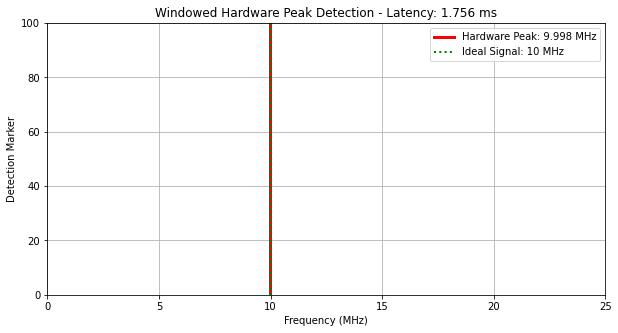

✅ 测试结束！请截图保存。


In [1]:
from pynq import Overlay, allocate
import numpy as np
import matplotlib.pyplot as plt
import time
import os

# ================= 1. 加载带汉明窗的新版硬件 =================
bit_path = "/home/xilinx/jupyter_notebooks/spectrum_window.bit"

if not os.path.exists(bit_path):
    print(f"❌ 找不到文件: {bit_path}")
    raise FileNotFoundError("请检查文件名和路径！")

print("正在加载带汉明窗的硬件平台...")
try:
    ol = Overlay(bit_path, ignore_version=True)
    print("✅ 带汉明窗的硬件平台加载成功！")
except Exception as e:
    print(f"❌ 加载失败: {e}")
    raise

# ⚠️ 核心缺失的一行：获取 DMA 控制器！
dma = ol.axi_dma_0
print("✅ 成功获取 DMA 控制器！")

# ================= 2. 配置参数 =================
N = 8192
fs = 100e6  # 采样率 100MHz

input_buffer = allocate(shape=(N,), dtype=np.uint32) 
output_buffer = allocate(shape=(2,), dtype=np.uint32) 

# ================= 3. 在 Python 端生成 10MHz 正弦波 =================
t = np.arange(N) / fs
i_data = (np.sin(2 * np.pi * 10e6 * t) * 30000).astype(np.int16)
q_data = np.zeros(N, dtype=np.int16)
input_buffer[:] = (q_data.astype(np.uint32) << 16) | (i_data.astype(np.uint32) & 0xFFFF)

# ================= 4. 强行启动 DMA 并执行双向传输 =================
print("⏳ 正在将信号发送给 FPGA 的加窗+FFT流水线...")

dma.recvchannel.stop(); dma.recvchannel.start()
dma.sendchannel.stop(); dma.sendchannel.start()

dma.sendchannel.transfer(input_buffer)
dma.recvchannel.transfer(output_buffer)

t1 = time.perf_counter()
dma.sendchannel.wait()
dma.recvchannel.wait()
t2 = time.perf_counter()

print(f"🚀 纯硬件处理耗时（含汉明窗）: {(t2-t1)*1000:.3f} ms")

# ================= 5. 解析硬件峰值检测结果 =================
peak_index = output_buffer[0] & 0xFFFF
peak_magnitude = output_buffer[1]
detected_freq = peak_index * (fs / N) / 1e6

print(f"📊 硬件捕获的峰值索引: {peak_index}")
print(f"📊 硬件捕获的峰值幅值: {peak_magnitude}")
print(f"🎯 硬件计算出的峰值频率: {detected_freq:.3f} MHz")

if abs(detected_freq - 10) < 0.1:
    print("✅ 完美！带窗硬件准确检测到了 10 MHz 信号！")
else:
    print("⚠️ 警告：检测到的频率偏离 10 MHz，请检查加窗模块连线或 ROM 配置！")

# ================= 6. 生成频谱图 =================
plt.figure(figsize=(10, 5))
plt.axvline(x=detected_freq, color='r', linestyle='-', linewidth=3,
            label=f'Hardware Peak: {detected_freq:.3f} MHz')
plt.axvline(x=10, color='g', linestyle=':', linewidth=2, label='Ideal Signal: 10 MHz')
plt.xlim(0, 25)
plt.ylim(0, 100)
plt.title(f"Windowed Hardware Peak Detection - Latency: {(t2-t1)*1000:.3f} ms")
plt.xlabel("Frequency (MHz)")
plt.ylabel("Detection Marker")
plt.grid(True)
plt.legend()
plt.show()

print("✅ 测试结束！请截图保存。")